In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns

# OBS Carpinetti: outras preditoras a considerar: certifications, n_awards e Co2_kg_per_unit

In [ ]:
suppliers_df = pd.read_excel("/content/supplier_recommender_textile (1).xlsx", sheet_name="SUPPLIERS")
plot_order = ['POOR', 'AVERAGE', 'GOOD']
suppliers_df_cleaned = suppliers_df[suppliers_df['performance_band'].isin(plot_order)]
predictors_quanti = [
    'sustainability_score', 'defect_rate_pct', 'on_time_delivery_pct',
    'avg_lead_time_days', 'price_index_vs_market', 'responsiveness_score',
    'innovation_score', 'financial_risk_prob_default', 'relationship_years'
]

df_clean = suppliers_df_cleaned.dropna(subset=predictors_quanti + ['avg_rating', 'performance_band']).copy()

X = df_clean[predictors_quanti]
scaler = MinMaxScaler()
X_normalized = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

print("Célula 1: Dados normalizados.")

print(f"Total de fornecedores na análise: {len(suppliers_df_cleaned)}")
print(f"Bandas de performance a serem analisadas: {plot_order}")

Célula 1: Dados normalizados.
Total de fornecedores na análise: 460
Bandas de performance a serem analisadas: ['POOR', 'AVERAGE', 'GOOD']


#1. Gráfico Boxplot: avg_rating vs. performance_band

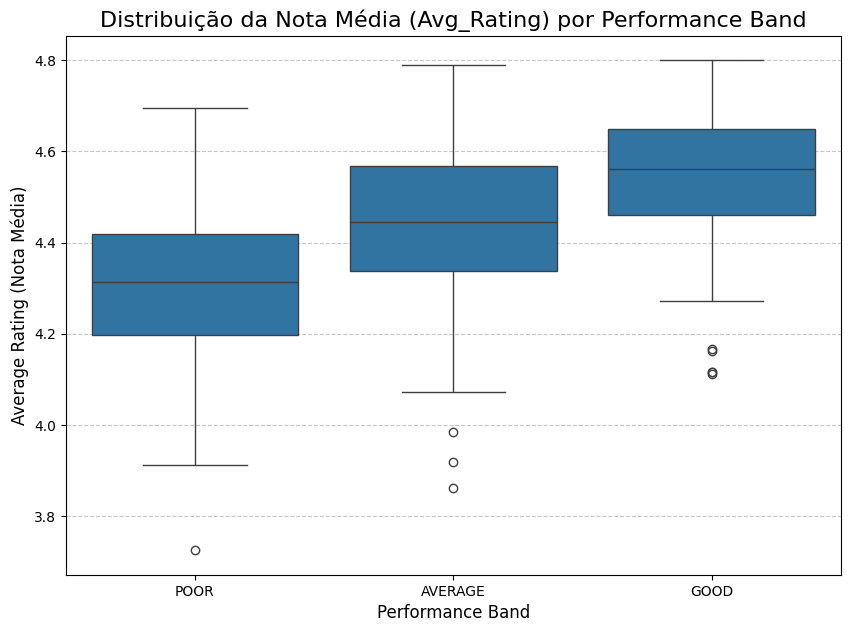

In [ ]:
plt.figure(figsize=(10, 7))
sns.boxplot(x='performance_band', y='avg_rating', data=suppliers_df_cleaned, order=plot_order)

plt.title('Distribuição da Nota Média (Avg_Rating) por Performance Band', fontsize=16)
plt.xlabel('Performance Band', fontsize=12)
plt.ylabel('Average Rating (Nota Média)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
filename_1 = 'boxplot_rating_vs_performance_band.png'
plt.savefig(filename_1)


# 2. Gráficos Boxplot: Preditores Quantitativos vs. performance_band



Gerando 8 gráficos de preditores...


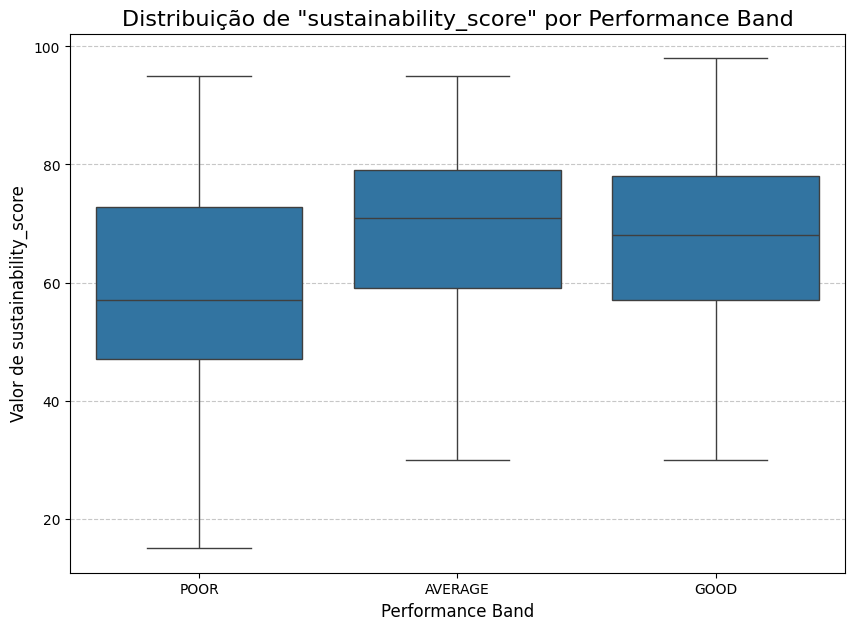

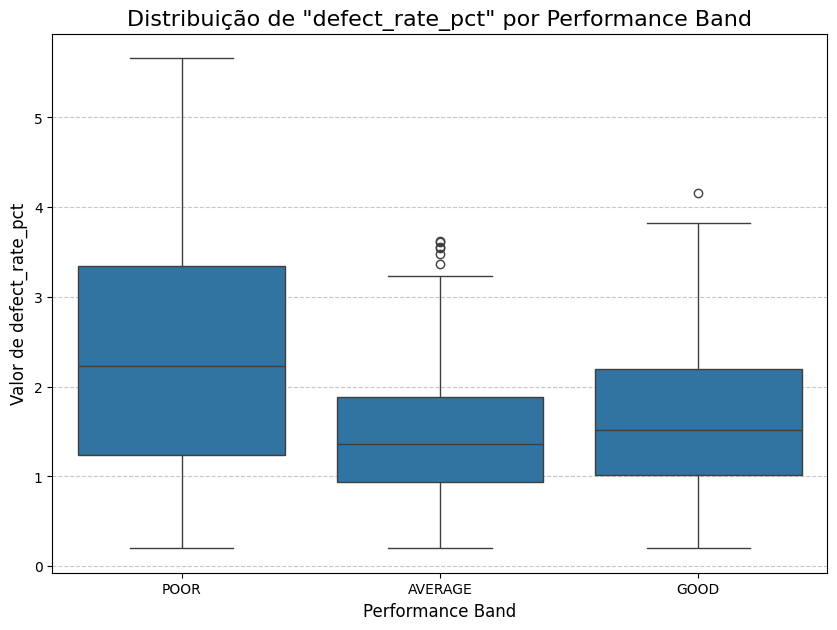

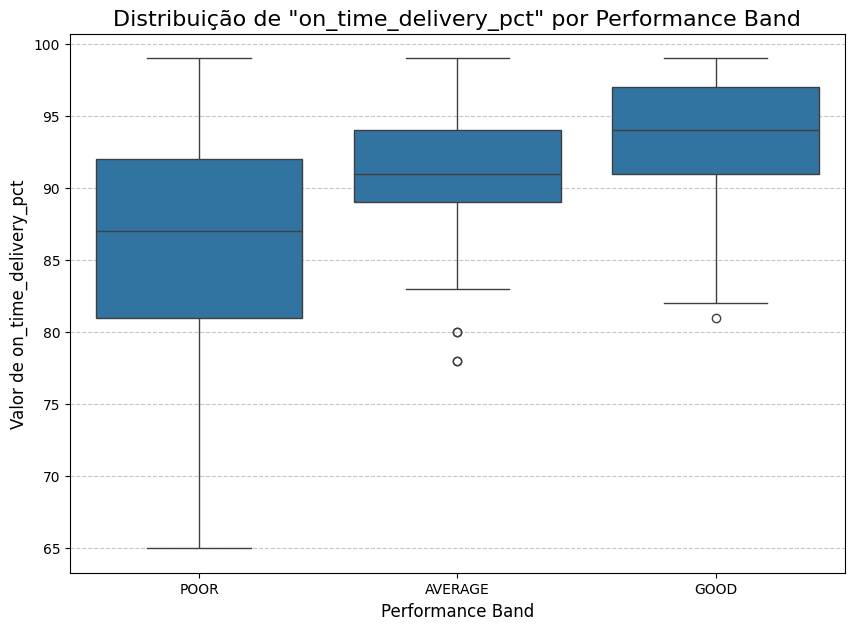

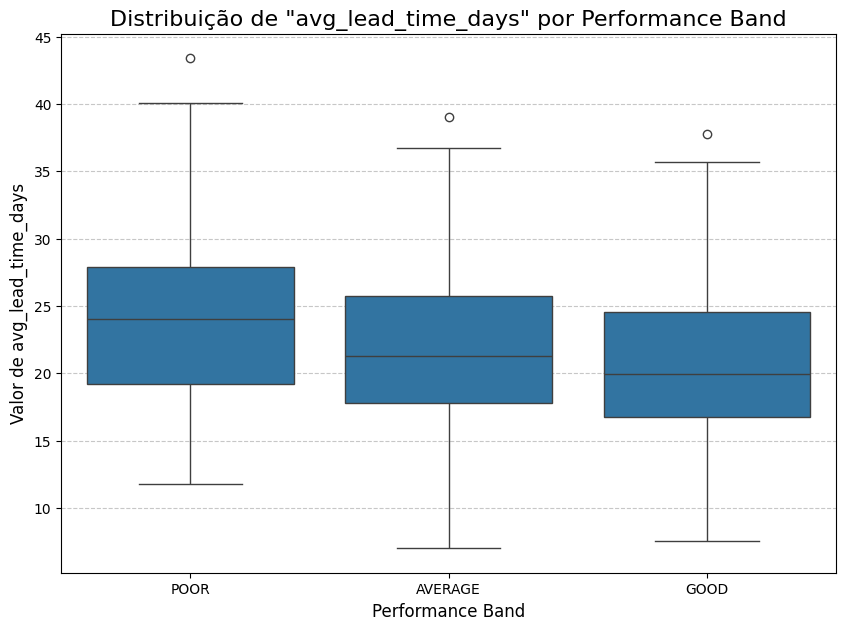

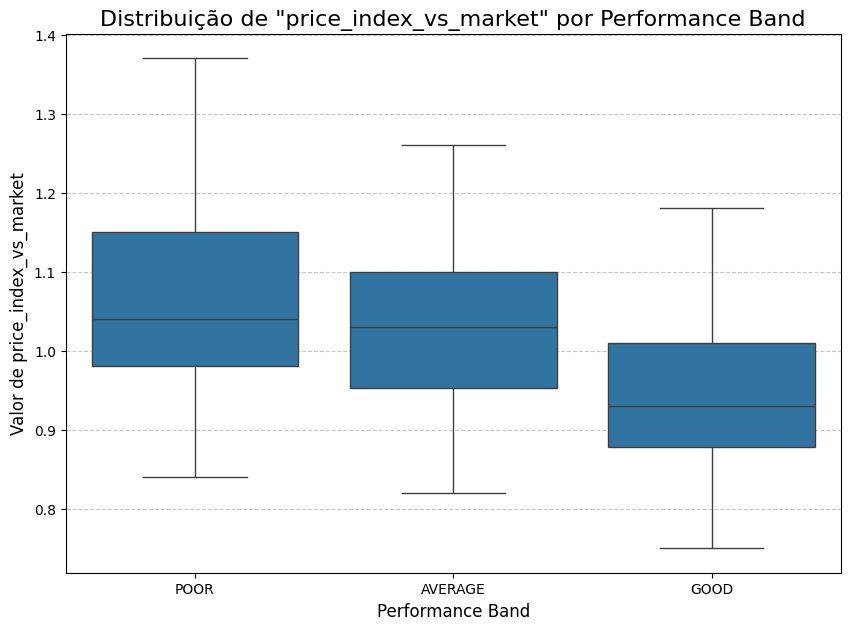

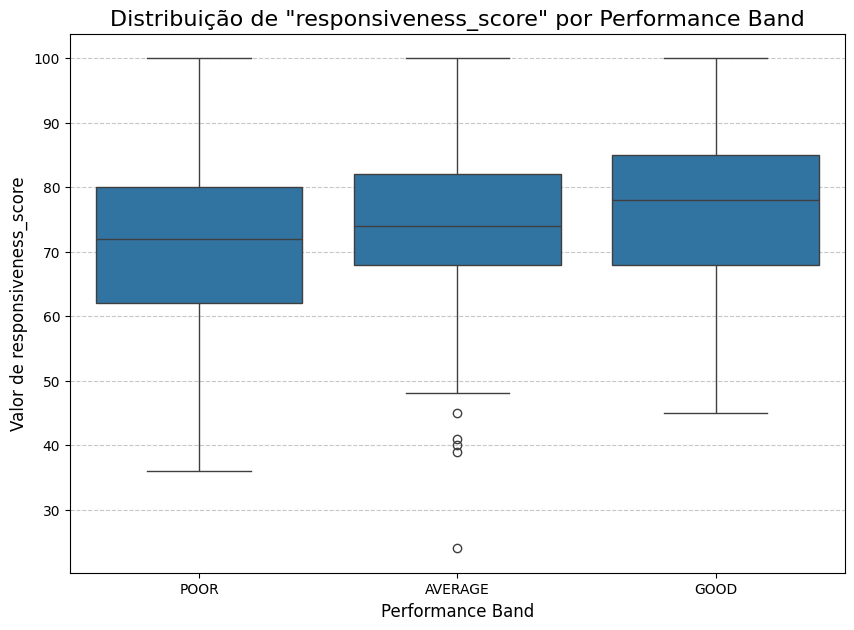

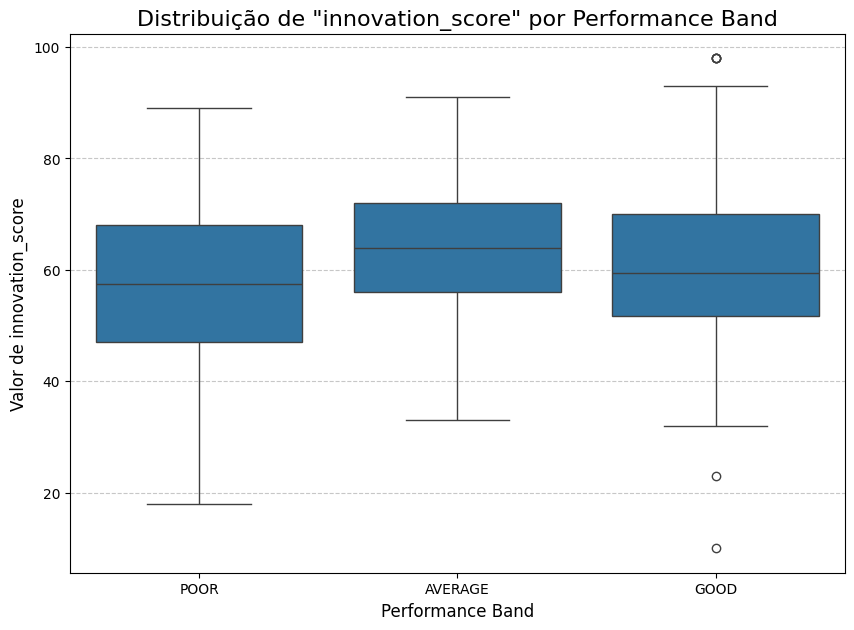

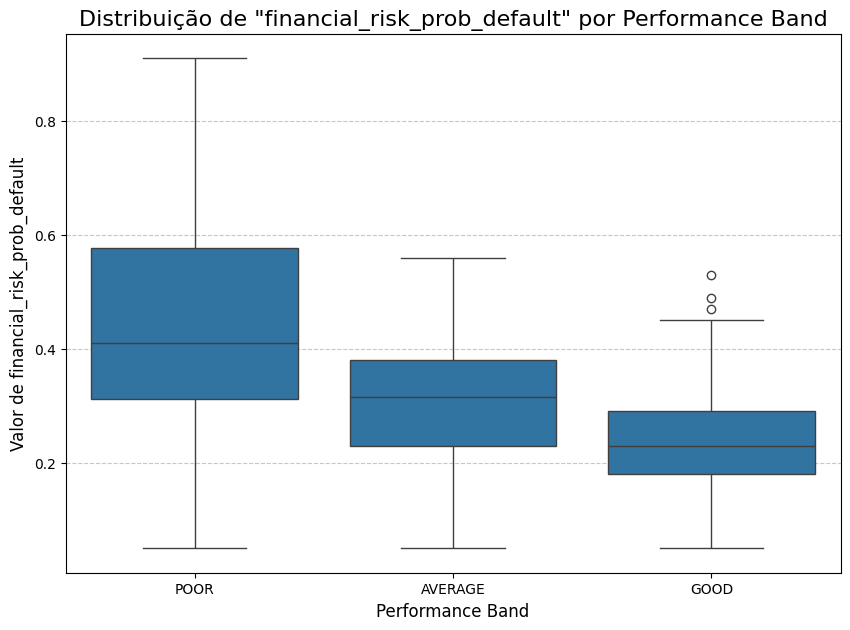

In [ ]:
predictors_quanti = [
    'sustainability_score',
    'defect_rate_pct',
    'on_time_delivery_pct',
    'avg_lead_time_days',
    'price_index_vs_market',
    'responsiveness_score',
    'innovation_score',
    'financial_risk_prob_default'
]
print(f"Gerando {len(predictors_quanti)} gráficos de preditores...")
for predictor in predictors_quanti:
    plt.figure(figsize=(10, 7))
    sns.boxplot(x='performance_band', y=predictor, data=suppliers_df_cleaned, order=plot_order)

    plt.title(f'Distribuição de "{predictor}" por Performance Band', fontsize=16)
    plt.xlabel('Performance Band', fontsize=12)
    plt.ylabel(f'Valor de {predictor}', fontsize=12)
    plt.grid(axis='y', linestyle='--', alpha=0.7)

# 3. Análise: Preditores Quantitativos vs. avg_rating



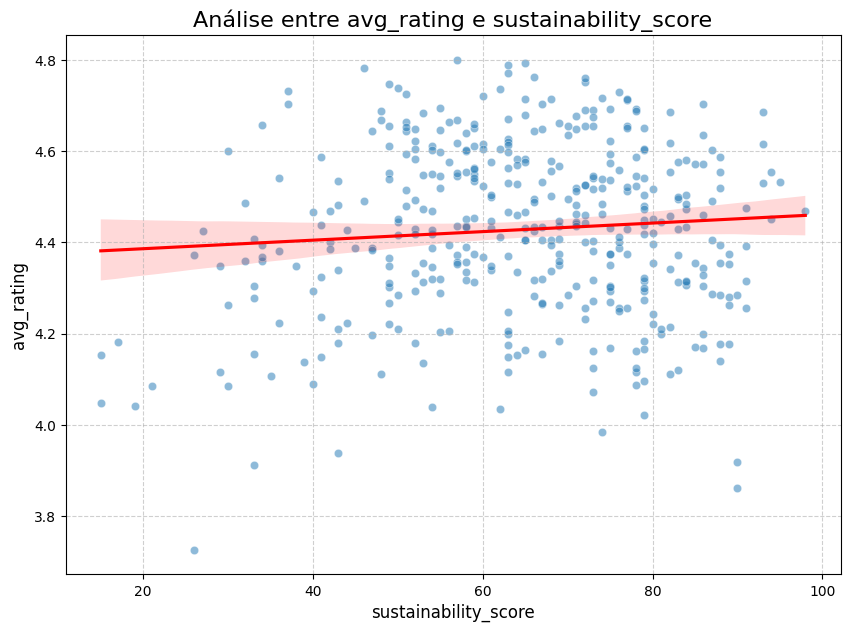

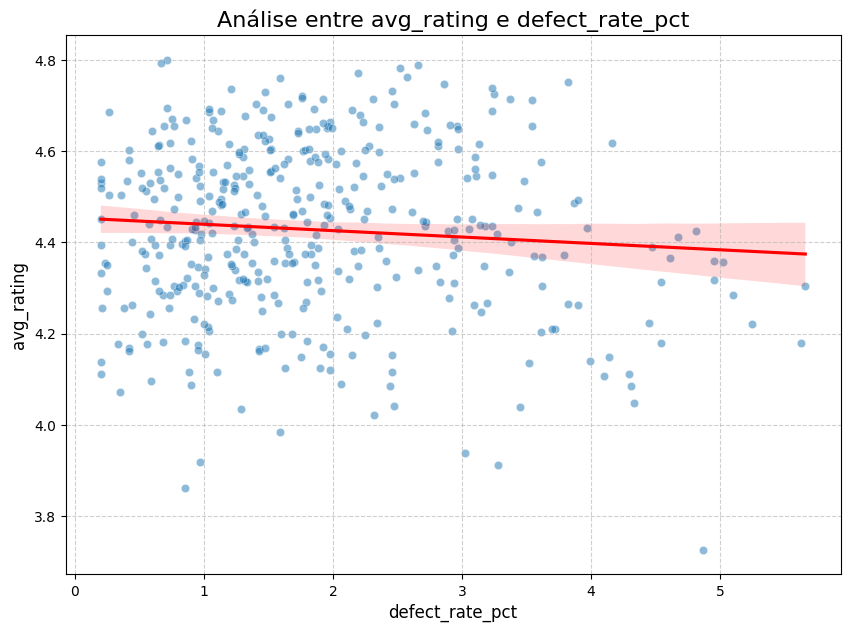

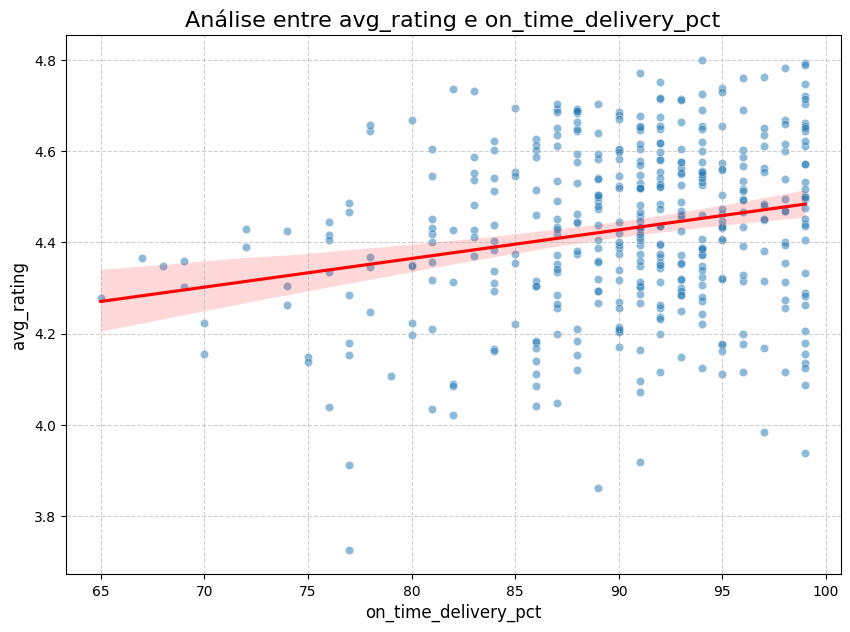

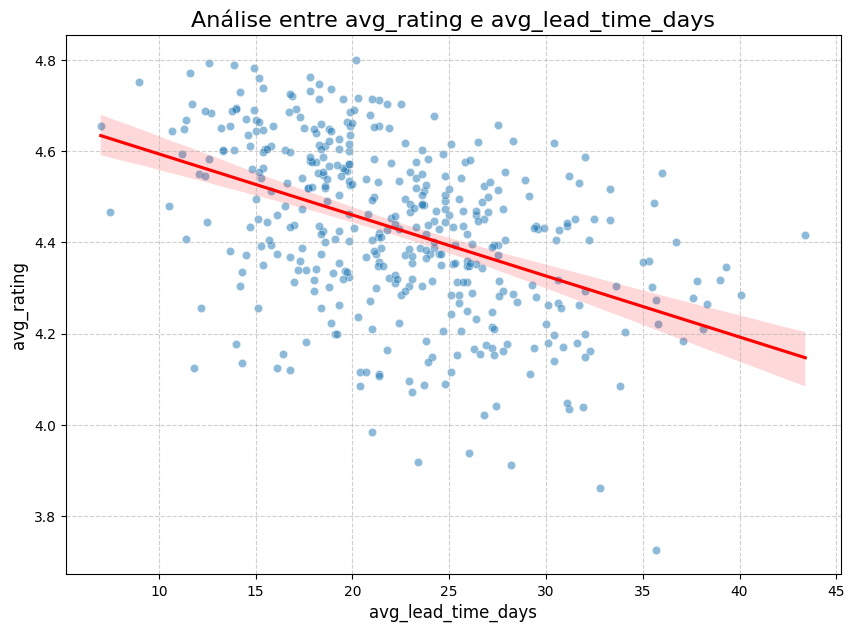

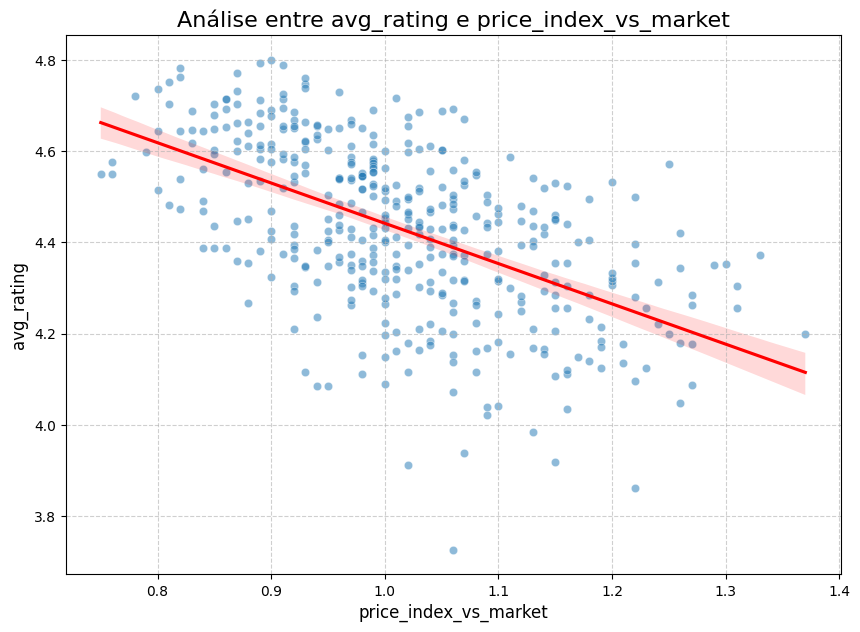

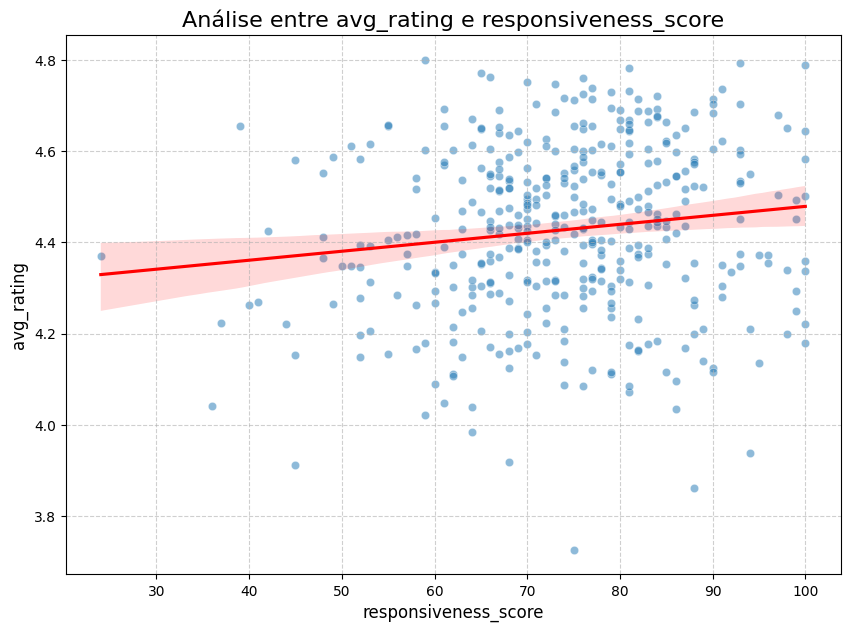

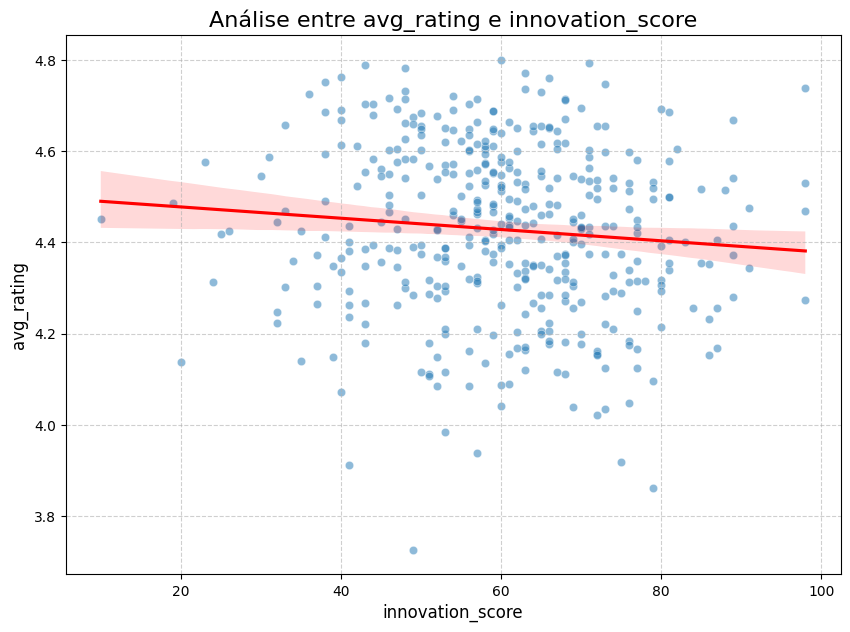

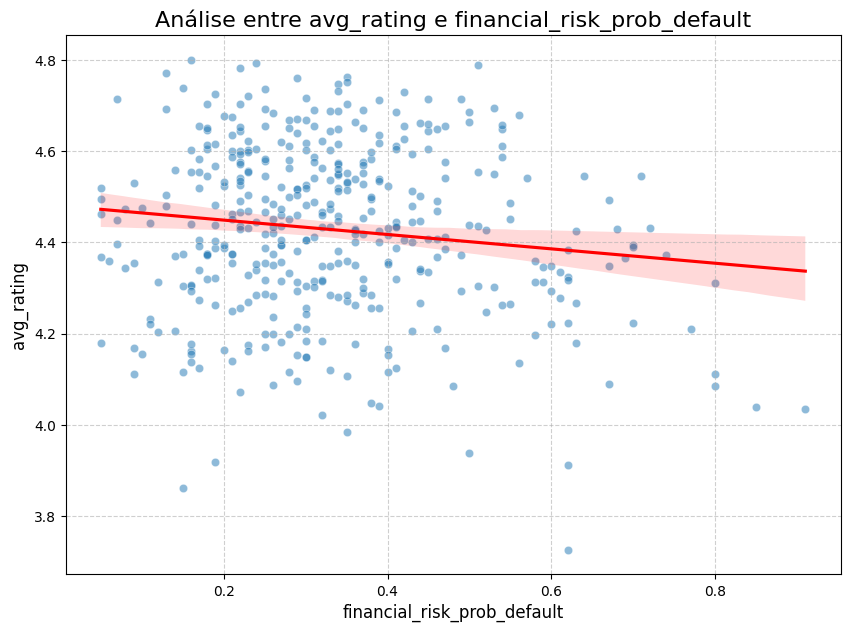

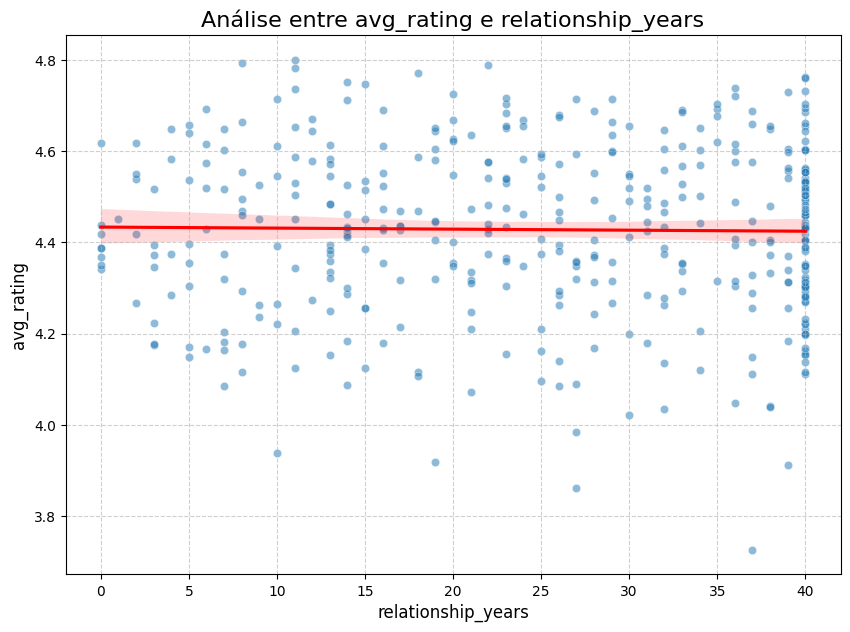

In [ ]:
predictors_quanti = [
    'sustainability_score',
    'defect_rate_pct',
    'on_time_delivery_pct',
    'avg_lead_time_days',
    'price_index_vs_market',
    'responsiveness_score',
    'innovation_score',
    'financial_risk_prob_default',
    'relationship_years'
]

target = 'avg_rating'

for predictor in predictors_quanti:
    plt.figure(figsize=(10, 7))
    sns.scatterplot(x=predictor, y=target, data=suppliers_df_cleaned, alpha=0.5)

    sns.regplot(x=predictor, y=target, data=suppliers_df_cleaned, scatter=False, color='red')

    plt.title(f'Análise entre {target} e {predictor}', fontsize=16)
    plt.xlabel(f'{predictor}', fontsize=12)
    plt.ylabel(f'{target}', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.6)


# 4. Análise de Clusters



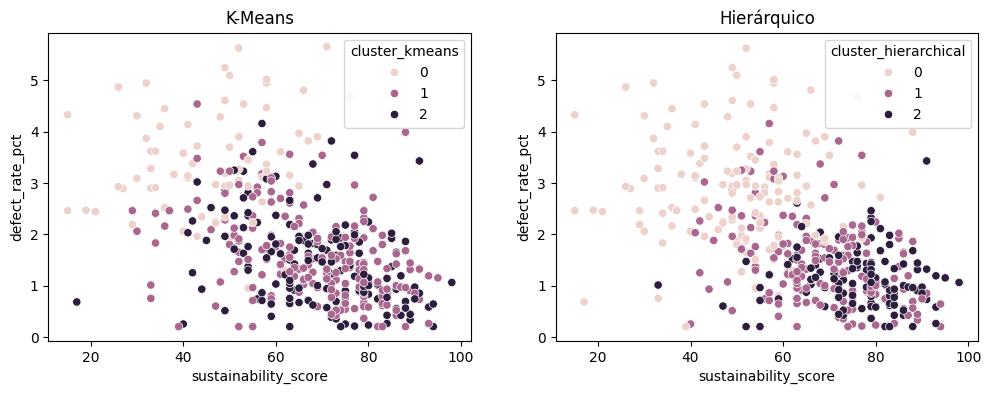

In [ ]:
from sklearn.cluster import KMeans, AgglomerativeClustering

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters_kmeans = kmeans.fit_predict(X_normalized)
df_clean['cluster_kmeans'] = clusters_kmeans

hierarchical = AgglomerativeClustering(n_clusters=3)
clusters_hierarchical = hierarchical.fit_predict(X_normalized)
df_clean['cluster_hierarchical'] = clusters_hierarchical

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.scatterplot(data=df_clean, x='sustainability_score', y='defect_rate_pct', hue='cluster_kmeans')
plt.title('K-Means')
plt.subplot(1, 2, 2)
sns.scatterplot(data=df_clean, x='sustainability_score', y='defect_rate_pct', hue='cluster_hierarchical')
plt.title('Hierárquico')
plt.show()

# 5. Ferramentas de Regressão



In [ ]:
y_reg = df_clean['avg_rating']
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X_normalized, y_reg, test_size=0.3, random_state=42)

#5.1 Regressão Linear

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

lin_reg = LinearRegression()
lin_reg.fit(X_train_reg, y_train_reg)
y_pred_lin = lin_reg.predict(X_test_reg)

print(f"Regressão Linear MSE: {mean_squared_error(y_test_reg, y_pred_lin):.4f}")
print(f"Regressão Linear R2: {r2_score(y_test_reg, y_pred_lin):.4f}")

Regressão Linear MSE: 0.0164
Regressão Linear R2: 0.4529


#5.2 K-Nearest Neighbors (KNN)

In [ ]:
from sklearn.neighbors import KNeighborsRegressor

knn_reg = KNeighborsRegressor(n_neighbors=5)
knn_reg.fit(X_train_reg, y_train_reg)
y_pred_knn = knn_reg.predict(X_test_reg)

print(f" KNN MSE: {mean_squared_error(y_test_reg, y_pred_knn):.4f}")

 KNN MSE: 0.0255


#5.3 Naive Bayes

In [ ]:
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

y_train_int = y_train_reg.round().astype(int)
y_test_int = y_test_reg.round().astype(int)

nb = GaussianNB()
nb.fit(X_train_reg, y_train_int)
y_pred_nb = nb.predict(X_test_reg)
print(f"Naive Bayes (Acurácia): {accuracy_score(y_test_int, y_pred_nb):.2%}")

Naive Bayes (Acurácia): 75.20%


#5.4 Regressão Logística

In [ ]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_reg, y_train_int)
y_pred_log = log_reg.predict(X_test_reg)
print(f"Regressão Logística (Acurácia): {accuracy_score(y_test_int, y_pred_log):.2%}")

Regressão Logística (Acurácia): 82.40%


#6. Ferramentas de Classificação

In [ ]:
y_class = df_clean['performance_band']
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_normalized, y_class, test_size=0.3, random_state=42)

#6.1 KNN

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn_class = KNeighborsClassifier(n_neighbors=5)
knn_class.fit(X_train_c, y_train_c)
print(f"Classificação Acurácia: {knn_class.score(X_test_c, y_test_c):.2%}")

Classificação Acurácia: 64.00%


#6.2 Naive Bayes

In [ ]:
from sklearn.naive_bayes import GaussianNB

nb_class = GaussianNB()
nb_class.fit(X_train_c, y_train_c)
print(f"Naive Bayes Classificação Acurácia: {nb_class.score(X_test_c, y_test_c):.2%}")

Naive Bayes Classificação Acurácia: 64.80%


#6.3 Árvores de Decisão (Decision tree)

In [ ]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train_c, y_train_c)
print(f"Árvore de Decisão Acurácia: {tree.score(X_test_c, y_test_c):.2%}")

Árvore de Decisão Acurácia: 63.20%


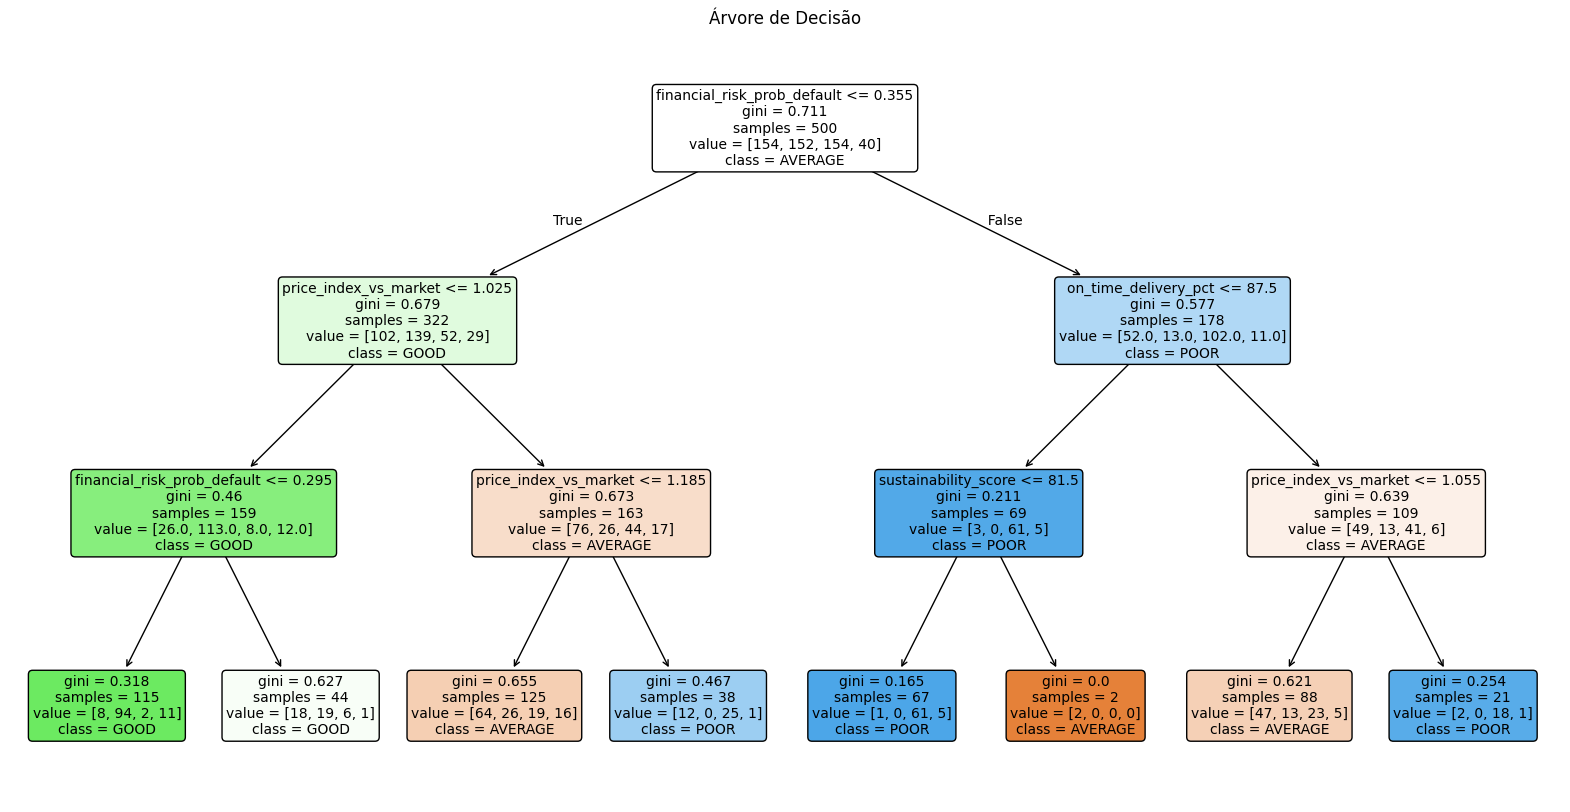

In [ ]:

df = pd.read_excel("/content/supplier_recommender_textile (1).xlsx", sheet_name="SUPPLIERS")

predictors_quanti = [
    'sustainability_score', 'defect_rate_pct', 'on_time_delivery_pct',
    'avg_lead_time_days', 'price_index_vs_market', 'responsiveness_score',
    'innovation_score', 'financial_risk_prob_default', 'relationship_years'
]
target_col = 'performance_band'

df_clean = df.dropna(subset=predictors_quanti + [target_col]).copy()

X = df_clean[predictors_quanti]
y = df_clean[target_col]

clf_tree = DecisionTreeClassifier(max_depth=3, random_state=42)
clf_tree.fit(X, y)

plt.figure(figsize=(20, 10))
plot_tree(clf_tree,
          feature_names=predictors_quanti,
          class_names=clf_tree.classes_,
          filled=True,
          rounded=True,
          fontsize=10)

plt.title("Árvore de Decisão")
plt.savefig('decision_tree_plot.png', dpi=300)
plt.show()

#6.4 Florestas Aleatórias (Random Forest)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(random_state=42)
forest.fit(X_train_c, y_train_c)
print(f"Random Forest Acurácia: {forest.score(X_test_c, y_test_c):.2%}")

Random Forest Acurácia: 78.40%


#6.5 SVM (Support Vector Machine)

In [ ]:
from sklearn.svm import SVC

svm_model = SVC(kernel='linear', random_state=42)
svm_model.fit(X_train_c, y_train_c)
print(f"SVM Acurácia: {svm_model.score(X_test_c, y_test_c):.2%}")

SVM Acurácia: 80.80%
